# 08 · Calibration, similarity features and fusion

Both classifiers read only the petition's own text, so they cannot see **whether a similar petition is open right
now**, which is exactly what makes a petition a duplicate. This notebook adds that information and combines
everything in a small **fusion model**, on validation predictions:

1. **Calibration:** make each classifier's confidence honest (temperature scaling, Platt scaling).
2. **Similarity features:** how close is the nearest open petition (MiniLM vectors, the pools of 04)?
3. **Fusion:** a multinomial logistic regression on [7 class probabilities + 4 similarity features].
4. **2×2 comparison:** {TF-IDF + SVC, DistilRoBERTa} × {text only, + similarity features}.
5. **Review threshold** and a **frozen configuration**, so that nothing can change after the test set is opened.

**The rule for honest numbers:** the fusion model is trained on validation, so scoring it on the same petitions
would flatter it. Every number here is **out-of-fold**: validation is cut into 5 parts, and each part is scored by a
model trained on the other 4. Calibration is fitted inside those folds too.

**Input** (in `data/processed/`): `petitions.parquet`, `out_of_scope.parquet`, `splits.parquet`, the MiniLM vectors,
and the validation predictions of 05 and `colab_gpu`.

**Output:**

| File | Content |
|---|---|
| `data/processed/predictions/similarity_features.parquet` | the 4 features for every petition (only the validation rows are read here) |
| `data/processed/predictions/fusion_val_oof.parquet` | out-of-fold probabilities of the final model |
| `models/fusion/fusion.joblib` | temperature, Platt scaler and the 4 fusion models, refitted on all of validation |
| `reports/frozen_config.json` | every chosen setting; notebook 09 reads it and changes nothing |
| `reports/fusion_val_results.csv`, `reports/figures/*.png` | the results table and three figures |

The first run takes about 5 minutes (the features of all petitions), later runs about 2. The test labels and texts
are not used; for test, only the pool sizes are looked at, which depend on dates alone.

In [1]:
import json, sys, time
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd().parent                      # this notebook runs inside notebooks/
sys.path.insert(0, str(ROOT / "src"))
from preprocess import CLASSES, leakage_check
from splits import CandidatePools
from fusion import (SIMILARITY_COLUMNS, PlattScaler, apply_temperature, expected_calibration_error,
                    fit_temperature, fusion_model, similarity_features)

DATA, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(exist_ok=True)
SEED = 42
C_GRID = [0.01, 0.1, 1, 10]     # for the fusion model, chosen by inner cross-validation
ECE_BINS = 15
BASES = ["tfidf_svc", "distilroberta"]

# Two decisions, explained in sections 6 and 7
CLIP_POOL_SIZE = True           # keep the pool size inside the range seen on validation
REVIEW_TARGET = 0.90            # petitions above the threshold should be about this accurate

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})

## 1. Load

In [2]:
columns = ["id", "label", "decision_time", "opened_at", "closed_at"]
petitions = pd.read_parquet(DATA / "petitions.parquet", columns=columns)
petitions = petitions.merge(pd.read_parquet(DATA / "splits.parquet"), on="id", validate="one_to_one")
out_of_scope = pd.read_parquet(DATA / "out_of_scope.parquet", columns=["id", "decision_time"])
pools = CandidatePools(petitions)

val = petitions[petitions["split"] == "val"].reset_index(drop=True)
y = val["label"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
ALL_LABELS = list(range(len(CLASSES)))

distilroberta = pd.read_parquet(DATA / "predictions" / "distilroberta_val.parquet").set_index("id")
tfidf_svc = pd.read_parquet(DATA / "predictions" / "tfidf_svc_val.parquet").set_index("id")
assert set(distilroberta.index) == set(val["id"]) == set(tfidf_svc.index)      # join on id, never on row position
LOGITS = distilroberta.loc[val["id"], [f"logit_{c}" for c in CLASSES]].to_numpy()
SCORES = tfidf_svc.loc[val["id"], [f"score_{c}" for c in CLASSES]].to_numpy()
print(f"{len(val):,} validation petitions; raw scores in CLASSES order: {LOGITS.shape}, {SCORES.shape}")

4,030 validation petitions; raw scores in CLASSES order: (4030, 7), (4030, 7)


## 2. Similarity features

For each petition, using the MiniLM vectors (the better vector model in 07) and its open pool at decision time:

| Feature | Meaning |
|---|---|
| `sim_top1` | cosine with the closest open petition |
| `sim_top5_mean` | average cosine with the 5 closest (a crowded topic?) |
| `sim_gap` | top-1 minus top-2: is one petition clearly the closest? |
| `pool_size` | how many petitions are open |

**The petition itself is never in its own pool.** Without this rule every published petition would have
top-1 = 1.0, a fake "published" signal; the asserts below check it. The features are computed once for all
petitions and stored.

In [3]:
sim_path = DATA / "predictions" / "similarity_features.parquet"
if not sim_path.exists():
    ids = np.load(DATA / "embeddings" / "minilm_ids.npy")
    vectors = np.load(DATA / "embeddings" / "minilm_vectors.npy", mmap_mode="r")
    row = pd.Series(np.arange(len(ids)), index=ids)
    pool_vectors = np.asarray(vectors[row.loc[pools.ids].to_numpy()])
    everyone = pd.concat([petitions[["id", "decision_time"]], out_of_scope], ignore_index=True)
    start, table = time.time(), []
    for first in range(0, len(everyone), 5000):                  # chunks keep memory low on the laptop
        part = everyone.iloc[first:first + 5000]
        part_vectors = np.asarray(vectors[row.loc[part["id"]].to_numpy()])
        for vector, query_id, t in zip(part_vectors, part["id"], part["decision_time"]):
            mask = pools.mask(t, query_id)
            assert query_id not in pools.ids[mask]
            table.append(similarity_features(vector, pool_vectors[mask]))
    features = pd.DataFrame(table, columns=SIMILARITY_COLUMNS).assign(id=everyone["id"].to_numpy())
    features.to_parquet(sim_path, index=False)
    print(f"computed for {len(features):,} petitions in {(time.time() - start) / 60:.1f} min")

sim = pd.read_parquet(sim_path).set_index("id").loc[val["id"]].reset_index(drop=True)
published = val["label"] == "published"
assert (sim["sim_top1"][published] >= 0.999).mean() < 0.001       # no self-match
print("published validation petitions with top-1 >= 0.999:", int((sim["sim_top1"][published] >= 0.999).sum()))
sim.assign(label=val["label"]).groupby("label")[SIMILARITY_COLUMNS].median().reindex(CLASSES).round(3)

published validation petitions with top-1 >= 0.999: 0


,sim_top1,sim_top5_mean,sim_gap,pool_size
label,,,,
published,0.637,0.577,0.031,1937.0
duplicate,0.734,0.625,0.058,1897.0
irrelevant,0.584,0.527,0.028,1897.0
no-action,0.633,0.578,0.032,1941.0
honours,0.559,0.499,0.027,1937.0
already-happening,0.634,0.578,0.031,1954.0
local,0.513,0.469,0.028,1946.5


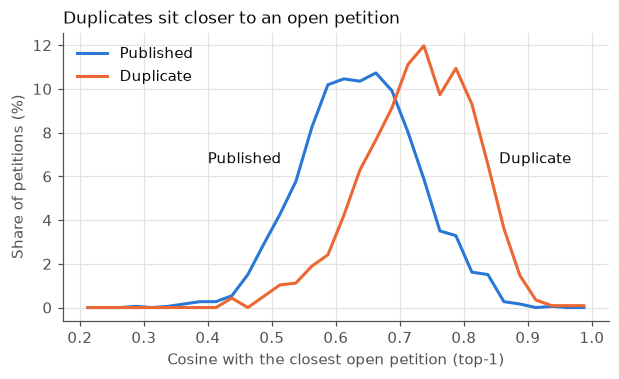

In [4]:
bins = np.arange(0.2, 1.0001, 0.025)
centres = (bins[:-1] + bins[1:]) / 2
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for label, colour, name in [("published", BLUE, "Published"), ("duplicate", ORANGE, "Duplicate")]:
    share = np.histogram(sim["sim_top1"][val["label"] == label], bins=bins)[0] / (val["label"] == label).sum()
    ax.plot(centres, share * 100, color=colour, linewidth=2, label=name)
ax.text(0.515, 6.6, "Published", color=INK, ha="right")
ax.text(0.855, 6.6, "Duplicate", color=INK, ha="left")
ax.set_xlabel("Cosine with the closest open petition (top-1)")
ax.set_ylabel("Share of petitions (%)")
ax.set_title("Duplicates sit closer to an open petition", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "similarity_top1_val.png")
plt.show()

## 3. Calibration in plain words

A model is **calibrated** if, among the petitions it gives 80% confidence, about 80% are right. A moderator can
then trust the number.

- **DistilRoBERTa, temperature scaling:** all logits are divided by one number T before the softmax. T > 1 lowers
  the confidence. The ranking of classes never changes, so macro-F1 stays the same. T is the value that gives the
  lowest log-loss on validation.
- **TF-IDF + SVC, Platt scaling:** one small sigmoid per class turns raw scores into probabilities (as in 05, but
  fitted inside the folds here). This can change the top class, so its macro-F1 can move.
- **ECE (expected calibration error)** measures the average gap between confidence and accuracy, over 15 bins.
  0 is perfect.

In [5]:
T = fit_temperature(LOGITS, y)
print(f"temperature on all validation: T = {T:.3f}")
print(f"DistilRoBERTa ECE: {expected_calibration_error(apply_temperature(LOGITS, 1.0), y, ECE_BINS):.3f} at T = 1, "
      f"{expected_calibration_error(apply_temperature(LOGITS, T), y, ECE_BINS):.3f} at T = {T:.2f} (same petitions; out-of-fold values below)")

temperature on all validation: T = 1.476
DistilRoBERTa ECE: 0.122 at T = 1, 0.048 at T = 1.48 (same petitions; out-of-fold values below)


## 4. Fusion and the 2×2 comparison

The **fusion model** is a multinomial logistic regression with standardised inputs: one weight per input and class.
It learns things like "high top-1 cosine → more likely duplicate". It also learns validation's class mix, which
differs from train (published 30% → 46%, local 0.2% → 3.7%), so it corrects a shift that the classifiers cannot see.

For each base model, four versions are scored, all out-of-fold on the same 5 folds:

| Version | What it is |
|---|---|
| raw | the classifier's own top class, as in 05 and `colab_gpu` |
| calibrated | the top class after temperature / Platt scaling |
| LR 7 probabilities | fusion on the class probabilities only ("text only" in the 2×2) |
| LR 7 + 4 similarity | fusion with the similarity features ("+ similarity" in the 2×2) |

The regularisation C of each fusion model is chosen by an inner 5-fold cross-validation **inside** the training part
of each outer fold, by macro-F1. Class weights are not used (the reason is in the sensitivity check below).

In [6]:
P_COLUMNS = [f"p_{c}" for c in CLASSES]
outer_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(y, y))

def macro_f1(truth, predicted):
    return f1_score(truth, predicted, average="macro", labels=ALL_LABELS, zero_division=0)

def calibrated(base, train, test):
    """Probabilities for the train and test rows, with the calibration fitted on the train rows only."""
    if base == "distilroberta":
        t = fit_temperature(LOGITS[train], y[train])
        return apply_temperature(LOGITS[train], t), apply_temperature(LOGITS[test], t)
    platt = PlattScaler().fit(SCORES[train], y[train])
    return platt.transform(SCORES[train]), platt.transform(SCORES[test])

def fusion_inputs(probabilities, rows, with_similarity, columns=SIMILARITY_COLUMNS):
    """The inputs as a table, passed through the leakage check, then as a plain array."""
    X = pd.DataFrame(probabilities, columns=P_COLUMNS)
    if with_similarity:
        for column in columns:
            X[column] = sim[column].to_numpy()[rows]
    leakage_check(X, allowed=P_COLUMNS + SIMILARITY_COLUMNS)
    return X.to_numpy()

def choose_C(X, labels, class_weight=None):
    """Inner 5-fold cross-validation: the C with the best macro-F1."""
    best_C, best_score = None, -1
    for C in C_GRID:
        predicted = np.zeros(len(labels), dtype=int)
        for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, labels):
            predicted[b] = fusion_model(C, class_weight).fit(X[a], labels[a]).predict(X[b])
        score = macro_f1(labels, predicted)
        if score > best_score:
            best_C, best_score = C, score
    return best_C

def out_of_fold(base, with_similarity, class_weight=None):
    """Out-of-fold probabilities of one fusion model, and the C chosen in each outer fold."""
    result, chosen = np.zeros((len(y), len(CLASSES))), []
    for train, test in outer_folds:
        p_train, p_test = calibrated(base, train, test)
        X_train = fusion_inputs(p_train, train, with_similarity)
        X_test = fusion_inputs(p_test, test, with_similarity)
        C = choose_C(X_train, y[train], class_weight)
        chosen.append(C)
        result[test] = fusion_model(C, class_weight).fit(X_train, y[train]).predict_proba(X_test)
    return result, chosen

def summary_row(base, version, predicted, probabilities=None, chosen=""):
    return {"base": base, "version": version, "macro_f1": macro_f1(y, predicted), "accuracy": (predicted == y).mean(),
            "duplicate_f1": f1_score(y == CLASSES.index("duplicate"), predicted == CLASSES.index("duplicate")),
            "ece": np.nan if probabilities is None else expected_calibration_error(probabilities, y, ECE_BINS),
            "C_per_fold": chosen}

rows, oof = [], {}
start = time.time()
for base in BASES:
    raw = LOGITS if base == "distilroberta" else SCORES
    rows.append(summary_row(base, "raw", raw.argmax(axis=1)))
    cal = np.zeros((len(y), len(CLASSES)))
    for train, test in outer_folds:
        cal[test] = calibrated(base, train, test)[1]
    rows.append(summary_row(base, "calibrated", cal.argmax(axis=1), cal))
    for with_similarity, version in [(False, "LR 7 probabilities"), (True, "LR 7 + 4 similarity")]:
        oof[base, with_similarity], chosen = out_of_fold(base, with_similarity)
        rows.append(summary_row(base, version, oof[base, with_similarity].argmax(axis=1), oof[base, with_similarity],
                                str(chosen)))
results = pd.DataFrame(rows)
print(f"{time.time() - start:.0f} s")
results.round(4)

21 s


,base,version,macro_f1,accuracy,duplicate_f1,ece,C_per_fold
0,tfidf_svc,raw,0.4452,0.6581,0.5616,NaN,
1,tfidf_svc,calibrated,0.4785,0.6928,0.6484,0.0541,
2,tfidf_svc,LR 7 probabilities,0.5046,0.7035,0.6523,0.0243,"[0.1, 1, 0.1, 10, 1]"
3,tfidf_svc,LR 7 + 4 similarity,0.5592,0.7454,0.7379,0.0196,"[0.1, 1, 0.1, 1, 1]"
4,distilroberta,raw,0.5560,0.6834,0.5486,NaN,
5,distilroberta,calibrated,0.5560,0.6834,0.5486,0.0490,
6,distilroberta,LR 7 probabilities,0.5752,0.7355,0.6669,0.0282,"[10, 10, 1, 1, 10]"
7,distilroberta,LR 7 + 4 similarity,0.6065,0.7767,0.7562,0.0155,"[1, 1, 0.1, 10, 10]"


In [7]:
two_by_two = results.pivot(index="base", columns="version", values="macro_f1").loc[BASES]
two_by_two = two_by_two[["LR 7 probabilities", "LR 7 + 4 similarity"]].rename(columns={"LR 7 probabilities": "text only", "LR 7 + 4 similarity": "+ similarity"})
assert (two_by_two["+ similarity"] > two_by_two["text only"]).all()
two_by_two.round(3)

version,text only,+ similarity
base,,
tfidf_svc,0.505,0.559
distilroberta,0.575,0.607


**Sensitivity check: class weights.** Weighting rare classes more in the fusion model raises macro-F1 a little,
but look at what it costs: accuracy falls, duplicates get worse, and the probabilities stop being calibrated. The
assistant must give **calibrated confidence**, so the final model has no class weights.

In [8]:
weighted, chosen = out_of_fold("distilroberta", True, class_weight="balanced")
pd.DataFrame([summary_row("distilroberta", "LR 7 + 4 similarity, no weights", oof["distilroberta", True].argmax(axis=1), oof["distilroberta", True]),
              summary_row("distilroberta", "LR 7 + 4 similarity, balanced weights", weighted.argmax(axis=1), weighted)]).drop(columns="C_per_fold").round(4)

,base,version,macro_f1,accuracy,duplicate_f1,ece
0,distilroberta,"LR 7 + 4 similarity, no weights",0.6065,0.7767,0.7562,0.0155
1,distilroberta,"LR 7 + 4 similarity, balanced weights",0.6208,0.7308,0.6758,0.1636


## 5. The final model, class by class

In [9]:
FINAL = ("distilroberta", True)
final_probabilities = oof[FINAL]
final_predicted = final_probabilities.argmax(axis=1)
per_class = pd.DataFrame({"raw DistilRoBERTa": f1_score(y, LOGITS.argmax(axis=1), average=None, labels=ALL_LABELS),
                          "final model": f1_score(y, final_predicted, average=None, labels=ALL_LABELS)}, index=CLASSES)
per_class["change"] = per_class["final model"] - per_class["raw DistilRoBERTa"]
print(per_class.round(3).to_string(), "\n")
print(classification_report(y, final_predicted, labels=ALL_LABELS, target_names=CLASSES, digits=3, zero_division=0))
pd.DataFrame(confusion_matrix(y, final_predicted, labels=ALL_LABELS), index=[f"true {c}" for c in CLASSES], columns=CLASSES)

                   raw DistilRoBERTa  final model  change
published                      0.839        0.905   0.066
duplicate                      0.549        0.756   0.208
irrelevant                     0.493        0.537   0.045
no-action                      0.436        0.479   0.044
honours                        0.788        0.750  -0.038
already-happening              0.168        0.077  -0.091
local                          0.620        0.741   0.121 

                   precision    recall  f1-score   support

        published      0.869     0.944     0.905      1855
        duplicate      0.727     0.788     0.756      1161
       irrelevant      0.576     0.504     0.537       278
        no-action      0.558     0.420     0.479       455
          honours      0.717     0.786     0.750        42
already-happening      0.308     0.044     0.077        91
            local      0.865     0.649     0.741       148

         accuracy                          0.777      4030
 

,published,duplicate,irrelevant,no-action,honours,already-happening,local
true published,1751,78,8,17,0,1,0
true duplicate,129,915,23,78,11,4,1
true irrelevant,36,54,140,32,1,1,14
true no-action,72,160,28,191,1,3,0
true honours,1,6,2,0,33,0,0
true already-happening,20,43,2,22,0,4,0
true local,7,3,40,2,0,0,96


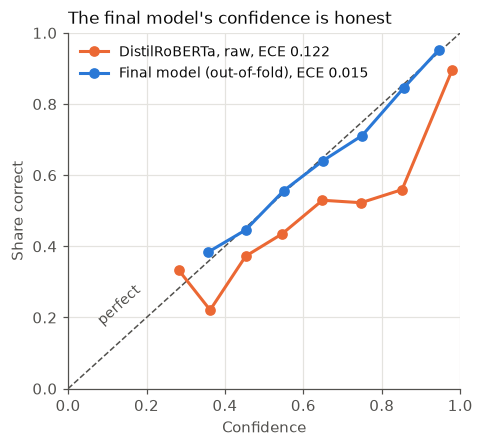

In [10]:
def reliability(probabilities, bins=10):
    """Mean confidence and accuracy per confidence bin (bins with at least 20 petitions)."""
    confidence, correct = probabilities.max(axis=1), probabilities.argmax(axis=1) == y
    points = []
    for low, high in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.sum() >= 20:
            points.append((confidence[in_bin].mean(), correct[in_bin].mean()))
    return np.array(points)

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax.text(0.13, 0.18, "perfect", color=MUTED, ha="center", rotation=42, fontsize=9)
for probabilities, colour, name in [(apply_temperature(LOGITS, 1.0), ORANGE, "DistilRoBERTa, raw"), (final_probabilities, BLUE, "Final model (out-of-fold)")]:
    points = reliability(probabilities)
    ece = expected_calibration_error(probabilities, y, ECE_BINS)
    ax.plot(points[:, 0], points[:, 1], color=colour, linewidth=2, marker="o", markersize=6, label=f"{name}, ECE {ece:.3f}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Confidence"); ax.set_ylabel("Share correct")
ax.set_title("The final model's confidence is honest", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.savefig(FIGURES / "reliability_val.png")
plt.show()

## 6. Decision: the pool-size feature

Pool size is a locked feature, but it grows with time, so the test petitions have larger pools than the model ever
saw on validation. Logistic regression keeps extrapolating a straight line, so a value far outside the training
range could push predictions in a way nothing has checked. The checks below use only dates (no test labels or texts):

1. **Ranges:** how far outside the validation range do test and out-of-scope petitions lie?
2. **What it adds:** out-of-fold scores with and without the feature.
3. **Stress check:** shift the validation petitions' pool size up to the test level, as if they were test petitions,
   and see how the predictions react, unclipped and clipped.

**Clipping** means: any pool size above the validation maximum is treated as the maximum (and below the minimum as
the minimum).

In [11]:
test_rows = petitions[petitions["split"] == "test"]
sizes = {"validation": sim["pool_size"].to_numpy(), "test": pools.sizes(test_rows["decision_time"], test_rows["id"]),
         "out of scope": pools.sizes(out_of_scope["decision_time"], out_of_scope["id"])}
POOL_LOW, POOL_HIGH = int(sizes["validation"].min()), int(sizes["validation"].max())
pd.DataFrame({name: {"min": s.min(), "median": np.median(s), "max": s.max(), "below val min": (s < POOL_LOW).sum(),
                     "above val max": (s > POOL_HIGH).sum(), "share outside": ((s < POOL_LOW) | (s > POOL_HIGH)).mean().round(3)}
              for name, s in sizes.items()}).T

,min,median,max,below val min,above val max,share outside
validation,1638.0,1929.0,2080.0,0.0,0.0,0.000
test,1804.0,2257.0,2503.0,0.0,3728.0,0.603
out of scope,61.0,1917.5,3753.0,298.0,384.0,0.770


In [12]:
def scored_with_pool(shift=0, clip=False, use_pool=True):
    """Out-of-fold scores of the final model when the test folds' pool size is shifted, and optionally clipped."""
    columns = SIMILARITY_COLUMNS if use_pool else SIMILARITY_COLUMNS[:3]
    result = np.zeros((len(y), len(CLASSES)))
    for (train, test), C in zip(outer_folds, [1] * 5):
        p_train, p_test = calibrated("distilroberta", train, test)
        X_train = fusion_inputs(p_train, train, True, columns)
        X_test = fusion_inputs(p_test, test, True, columns)
        if use_pool:
            X_test[:, -1] += shift
            if clip:
                X_test[:, -1] = np.clip(X_test[:, -1], POOL_LOW, POOL_HIGH)
        result[test] = fusion_model(C).fit(X_train, y[train]).predict_proba(X_test)
    return result

SHIFT = int(np.median(sizes["test"]) - np.median(sizes["validation"]))
base = scored_with_pool()
checks = {"without the pool-size feature": scored_with_pool(use_pool=False), "with it, no shift": base,
          f"shifted +{SHIFT}, not clipped": scored_with_pool(shift=SHIFT), f"shifted +{SHIFT}, clipped": scored_with_pool(shift=SHIFT, clip=True)}
pool_checks = pd.DataFrame([{"case": name, "macro_f1": macro_f1(y, p.argmax(axis=1)), "accuracy": (p.argmax(axis=1) == y).mean(),
                             "predictions changed": (p.argmax(axis=1) != base.argmax(axis=1)).mean(),
                             "ece": expected_calibration_error(p, y, ECE_BINS)} for name, p in checks.items()])
print(f"C = 1 in all four cases, so the comparison is fair; +{SHIFT} is the gap between the test and validation medians")
pool_checks.round(4)

C = 1 in all four cases, so the comparison is fair; +328 is the gap between the test and validation medians


,case,macro_f1,accuracy,predictions changed,ece
0,without the pool-size feature,0.6085,0.7787,0.0107,0.0165
1,"with it, no shift",0.6089,0.7777,0.0000,0.0167
2,"shifted +328, not clipped",0.6027,0.7702,0.0370,0.0262
3,"shifted +328, clipped",0.6109,0.7759,0.0174,0.0171


## 7. Decision: the review threshold

The assistant flags a petition **for closer review** when its confidence is below a threshold. The moderator always
decides, but a good flag tells them where to look harder. The curve shows the trade-off on the out-of-fold
probabilities: a higher threshold means the unflagged petitions are more accurate, but fewer of them.

The rule: the **lowest threshold whose unflagged petitions reach `REVIEW_TARGET` accuracy**.

In [13]:
confidence = final_probabilities.max(axis=1)
correct = final_predicted == y
thresholds = np.round(np.arange(0.30, 0.96, 0.05), 2)
curve = pd.DataFrame({"threshold": thresholds,
                      "not flagged": [(confidence >= t).mean() for t in thresholds],
                      "accuracy if not flagged": [correct[confidence >= t].mean() for t in thresholds],
                      "macro_f1 if not flagged": [macro_f1(y[confidence >= t], final_predicted[confidence >= t]) for t in thresholds]})
REVIEW_THRESHOLD = float(curve.loc[curve["accuracy if not flagged"] >= REVIEW_TARGET, "threshold"].min())
chosen_row = curve[curve["threshold"] == REVIEW_THRESHOLD].iloc[0]
print(f"threshold {REVIEW_THRESHOLD}: {chosen_row['not flagged']:.1%} of petitions not flagged, "
      f"{chosen_row['accuracy if not flagged']:.1%} of them correct; overall accuracy {correct.mean():.1%}")
curve.round(3)

threshold 0.75: 62.8% of petitions not flagged, 90.5% of them correct; overall accuracy 77.7%


,threshold,not flagged,accuracy if not flagged,macro_f1 if not flagged
0,0.30,0.999,0.778,0.607
1,0.35,0.985,0.783,0.611
2,0.40,0.963,0.792,0.608
3,0.45,0.926,0.809,0.621
4,0.50,0.887,0.822,0.631
5,0.55,0.842,0.838,0.636
6,0.60,0.793,0.854,0.646
7,0.65,0.742,0.870,0.655
8,0.70,0.691,0.885,0.655
9,0.75,0.628,0.905,0.633


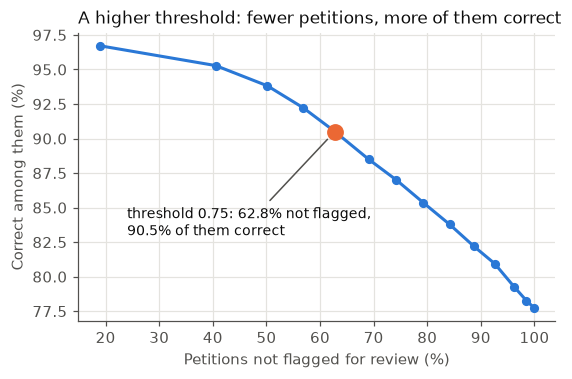

In [14]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(curve["not flagged"] * 100, curve["accuracy if not flagged"] * 100, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.plot(chosen_row["not flagged"] * 100, chosen_row["accuracy if not flagged"] * 100, color=ORANGE, marker="o", markersize=10, linestyle="none")
ax.annotate(f"threshold {REVIEW_THRESHOLD:.2f}: {chosen_row['not flagged']:.1%} not flagged,\n{chosen_row['accuracy if not flagged']:.1%} of them correct",
            (chosen_row["not flagged"] * 100, chosen_row["accuracy if not flagged"] * 100), xytext=(24, 83), textcoords="data", ha="left", color=INK, fontsize=9,
            arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1, "shrinkB": 7})
ax.set_xlabel("Petitions not flagged for review (%)")
ax.set_ylabel("Correct among them (%)")
ax.set_title("A higher threshold: fewer petitions, more of them correct", loc="left", fontsize=11)
fig.savefig(FIGURES / "coverage_accuracy_val.png")
plt.show()

## 8. Freeze

Everything is refitted on **all** of validation and saved. Notebook 09 and the pipeline read these files and change
nothing, so the test set cannot influence any choice. The saved models are loaded again as a check.

In [15]:
temperature = fit_temperature(LOGITS, y)
platt = PlattScaler().fit(SCORES, y)
probabilities = {"distilroberta": apply_temperature(LOGITS, temperature), "tfidf_svc": platt.transform(SCORES)}
every_row = np.arange(len(y))
fusion, fusion_C = {}, {}
for base in BASES:
    for with_similarity in [False, True]:
        X = fusion_inputs(probabilities[base], every_row, with_similarity)
        name = f"{base}+similarity" if with_similarity else base
        fusion_C[name] = choose_C(X, y)
        fusion[name] = fusion_model(fusion_C[name]).fit(X, y)

(ROOT / "models" / "fusion").mkdir(exist_ok=True)
joblib.dump({"temperature": temperature, "platt": platt, "fusion": fusion, "classes": CLASSES}, ROOT / "models" / "fusion" / "fusion.joblib")

bm25_table = pd.read_csv(REPORTS / "bm25_val_results.csv").query("pool == 'open'")
alpha_table = pd.read_csv(REPORTS / "hybrid_alpha_val.csv")
config = {
    "frozen_on_validation": True,
    "classes": CLASSES,
    "classification": {"final_model": "distilroberta+similarity", "tfidf_svc_C": json.load(open(REPORTS / "tfidf_svc_environment.json"))["best_C"],
                       "temperature": round(temperature, 4), "fusion_C": fusion_C, "fusion_class_weight": None,
                       "similarity_columns": SIMILARITY_COLUMNS, "similarity_vectors": "all-MiniLM-L6-v2",
                       "pool_size_clip": [POOL_LOW, POOL_HIGH] if CLIP_POOL_SIZE else None},
    "retrieval": {"final_method": "hybrid", "embedding_model": "all-MiniLM-L6-v2",
                  "bm25_k1": float(bm25_table.sort_values("mrr").iloc[-1]["k1"]), "bm25_b": 0.75,
                  "alpha": float(alpha_table.sort_values("mrr").iloc[-1]["alpha"])},
    "review": {"threshold": REVIEW_THRESHOLD, "target_accuracy": REVIEW_TARGET},
    "evaluation": {"ece_bins": ECE_BINS, "bootstrap_resamples": 1000},
    "seeds": {"random_state": SEED, "folds": "StratifiedKFold(5, shuffle=True, random_state=42)"},
}
with open(REPORTS / "frozen_config.json", "w") as f:
    json.dump(config, f, indent=2)

pd.DataFrame({"id": val["id"].to_numpy(), **{c: final_probabilities[:, i] for i, c in enumerate(P_COLUMNS)}}).to_parquet(DATA / "predictions" / "fusion_val_oof.parquet", index=False)
results.round(4).to_csv(REPORTS / "fusion_val_results.csv", index=False)

saved = joblib.load(ROOT / "models" / "fusion" / "fusion.joblib")
check = fusion_inputs(apply_temperature(LOGITS, saved["temperature"]), every_row, True)
assert np.allclose(saved["fusion"]["distilroberta+similarity"].predict_proba(check), fusion["distilroberta+similarity"].predict_proba(check))
print(json.dumps(config, indent=2))

{
  "frozen_on_validation": true,
  "classes": [
    "published",
    "duplicate",
    "irrelevant",
    "no-action",
    "honours",
    "already-happening",
    "local"
  ],
  "classification": {
    "final_model": "distilroberta+similarity",
    "tfidf_svc_C": 0.1,
    "temperature": 1.4757,
    "fusion_C": {
      "tfidf_svc": 1,
      "tfidf_svc+similarity": 0.1,
      "distilroberta": 1,
      "distilroberta+similarity": 10
    },
    "fusion_class_weight": null,
    "similarity_columns": [
      "sim_top1",
      "sim_top5_mean",
      "sim_gap",
      "pool_size"
    ],
    "similarity_vectors": "all-MiniLM-L6-v2",
    "pool_size_clip": [
      1638,
      2080
    ]
  },
  "retrieval": {
    "final_method": "hybrid",
    "embedding_model": "all-MiniLM-L6-v2",
    "bm25_k1": 2.0,
    "bm25_b": 0.75,
    "alpha": 0.1
  },
  "review": {
    "threshold": 0.75,
    "target_accuracy": 0.9
  },
  "evaluation": {
    "ece_bins": 15,
    "bootstrap_resamples": 1000
  },
  "seeds": {
   

## Summary

All numbers are out-of-fold on the 4,030 validation petitions.

- **The similarity features carry the signal the classifiers lack:** the median top-1 cosine is 0.734 for duplicates
  and 0.637 for published petitions. No published petition matches itself (0 with top-1 ≥ 0.999).
- **Calibration:** T = 1.48, so DistilRoBERTa was overconfident. ECE falls from 0.122 (raw) to 0.049 (temperature
  scaling) and 0.015 (fusion).
- **2×2 comparison (macro-F1):**

| | text only | + similarity |
|---|---|---|
| TF-IDF + SVC | 0.505 | 0.559 |
| DistilRoBERTa | 0.575 | **0.607** |

- **Final model: DistilRoBERTa + similarity.** Macro-F1 0.607 and accuracy 0.777, against 0.556 and 0.683 for raw
  DistilRoBERTa.
- **Class by class, against raw DistilRoBERTa:** duplicate 0.549 → 0.756, local 0.620 → 0.741, published 0.839 → 0.905,
  irrelevant 0.493 → 0.537, no-action 0.436 → 0.479. **What gets worse:** honours 0.788 → 0.750 and already-happening
  0.168 → 0.077. Whether something is already happening depends on outside knowledge, so that class stays very weak.
- **No class weights in the fusion model:** balanced weights give macro-F1 0.621, but accuracy falls to 0.731,
  duplicate F1 to 0.676, and ECE rises to 0.164, so the confidence would no longer be honest.
- **Pool size:** it adds almost nothing (0.609 with and without it). 60.3% of test petitions lie above the validation
  maximum. With pool sizes shifted to the test level, macro-F1 falls to 0.603 and ECE rises to 0.026; clipped, they
  stay at 0.611 and 0.017. So it is clipped to the validation range, 1,638–2,080.
- **Review threshold 0.75:** 62.8% of petitions are not flagged, and 90.5% of those are correct. The other 37.2% are
  flagged for closer review.
- **Frozen:** `reports/frozen_config.json` and `models/fusion/fusion.joblib`.

The folds mix petitions from the whole of July–December 2025, while the test petitions come later, so the test
result may be lower. It is measured once, in 09.
